# CV04 — Trâm: notebook phân tích

Notebook này đọc kết quả đã chạy; có thể chạy tất cả các ô để kiểm tra lại bảng và hình. Báo cáo đầy đủ nằm ở phần dưới.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
elif not (ROOT / 'outputs/tables/cv04_strategy_summary.csv').exists():
    ROOT = ROOT / 'time-series-lab2'
TABLES = ROOT / 'outputs/tables'
assert TABLES.exists(), 'Chạy notebook từ time-series-lab2 hoặc notebooks.'
pd.set_option('display.max_columns', 20)
display(pd.read_csv(TABLES / 'cv04_ablation_summary.csv'))


,variant,n_features,fit_seconds,predict_seconds,best_n_estimators,hit_tree_budget,validation_rmse,n,MAE,RMSE,MAPE_pct,WAPE_pct,R2,Bias_MW,Median_AE,P90_AE,P95_AE,Max_AE
0,lags_calendar,32,3.190046,0.049664,1000,True,205.658606,24221,163.234953,212.101541,1.127056,1.109137,0.992476,17.619556,132.824219,342.679688,419.825195,2980.254883
1,plus_rolling_24,34,3.379409,0.045850,1000,True,197.960571,24221,156.368665,204.025607,1.079303,1.062482,0.993038,17.157263,125.870117,327.834961,404.792969,2990.322266
2,plus_rolling_168,34,3.156387,0.038102,1000,True,200.692276,24221,158.644088,206.826549,1.094840,1.077943,0.992846,17.320624,128.302734,333.688477,411.424805,2983.437500
3,plus_all_rolling,36,3.412184,0.041218,1000,True,200.440340,24221,158.547856,206.719521,1.093837,1.077289,0.992853,16.309642,127.994141,333.817383,410.103516,2992.532227


## So sánh chiến lược

In [2]:
display(pd.read_csv(TABLES / 'cv04_strategy_summary.csv'))

,strategy,scope,n,MAE,RMSE,MAPE_pct,WAPE_pct,R2,Bias_MW,Median_AE,P90_AE,P95_AE,Max_AE
0,Direct,all,24144,568.330105,772.732318,3.910794,3.861050,0.900235,108.967449,414.256836,1287.376660,1659.112451,3923.218750
1,Recursive,all,24144,613.824836,847.288482,4.160272,4.170127,0.880055,20.252169,435.805664,1421.389844,1812.568750,4869.238281
2,SeasonalNaive168,all,24144,1435.360255,1909.356580,9.628682,9.751371,0.390893,-16.613486,1084.000000,3260.000000,3975.850000,8276.000000
3,SeasonalNaive24,all,24144,922.171057,1222.532283,6.250308,6.264931,0.750288,-3.757828,688.500000,2061.700000,2547.850000,7656.000000


## Sai số theo horizon

In [3]:
display(pd.read_csv(TABLES / 'cv04_error_by_horizon.csv'))

,strategy,horizon,n,MAE,RMSE,MAPE_pct,WAPE_pct,R2,Bias_MW,Median_AE,P90_AE,P95_AE,Max_AE
0,Direct,1,1006,135.622263,173.149063,0.885831,0.859378,0.995155,-4.050158,113.803711,272.601074,345.224121,739.714844
1,Direct,2,1006,287.329930,364.621643,1.847770,1.796435,0.977757,-31.918410,236.741699,576.018066,709.814209,1396.046875
2,Direct,3,1006,391.121948,491.122512,2.483942,2.433484,0.956862,-28.533819,324.333496,794.619629,945.401123,2057.818359
3,Direct,4,1006,435.359722,552.391356,2.766766,2.723552,0.936199,32.288194,354.008789,903.863281,1056.638672,2383.700195
4,Direct,5,1006,453.255470,590.516784,2.873015,2.857924,0.912826,31.887265,350.028809,970.925293,1162.206055,2289.607422
...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,SeasonalNaive24,20,1006,986.733598,1304.324337,6.381426,6.343087,0.557168,-3.846918,757.500000,2237.500000,2624.250000,4461.000000
92,SeasonalNaive24,21,1006,990.235586,1308.648139,6.358405,6.324710,0.608518,-3.837972,749.000000,2290.500000,2736.000000,4193.000000
93,SeasonalNaive24,22,1006,1022.735586,1342.382427,6.545263,6.499330,0.645605,-4.113320,752.000000,2300.500000,2809.750000,4325.000000
94,SeasonalNaive24,23,1006,1021.757455,1333.469913,6.563343,6.500907,0.686740,-4.844930,753.000000,2232.000000,2773.000000,4580.000000


## Mức tải và thiên lệch

In [4]:
display(pd.read_csv(TABLES / 'cv04_error_by_load_regime.csv'))

,strategy,load_regime,n,MAE,RMSE,MAPE_pct,WAPE_pct,R2,Bias_MW,Median_AE,P90_AE,P95_AE,Max_AE
0,Direct,low,9163,525.843918,729.084732,4.290316,4.253386,0.468668,362.544703,377.320312,1183.172656,1547.784277,3923.218750
1,Direct,middle,11353,561.963010,748.917188,3.681115,3.679887,0.434157,83.053148,425.548828,1264.148828,1600.942773,3159.060547
2,Direct,high,3628,695.559034,935.987037,3.670989,3.671398,0.358967,-450.382969,512.578125,1611.375000,1977.787256,3747.526367
3,Recursive,low,9163,509.979587,703.537008,4.135693,4.125064,0.505252,267.968638,379.893555,1096.424023,1504.040918,4587.224609
4,Recursive,middle,11353,630.563488,851.483364,4.116236,4.129101,0.268556,-12.328953,461.143555,1442.758594,1787.249609,4497.408203
5,Recursive,high,3628,823.720127,1121.894118,4.360151,4.347877,0.079032,-503.433750,596.537109,1929.898633,2344.656641,4869.238281
6,SeasonalNaive168,low,9163,1130.177780,1609.879113,9.170841,9.141652,-1.590578,573.314308,753.000000,2625.400000,3449.800000,7749.000000
7,SeasonalNaive168,middle,11353,1453.178895,1874.114923,9.461216,9.515811,-2.543407,-1.093984,1168.000000,3180.800000,3863.400000,7292.000000
8,SeasonalNaive168,high,3628,2150.380099,2593.208924,11.309064,11.350442,-3.920572,-1555.119901,1960.500000,4048.900000,4802.550000,8276.000000
9,SeasonalNaive24,low,9163,760.947288,1019.707230,6.141970,6.155063,-0.039348,316.587471,561.000000,1701.800000,2188.000000,4671.000000


## Bất định của mức cải thiện

In [5]:
display(pd.read_csv(TABLES / 'cv04_strategy_bootstrap.csv'))

,reference,candidate,block_length,repetitions,MAE_reduction_MW,CI95_low_MW,CI95_high_MW,candidate_win_rate_pct
0,Recursive,Direct,1,2000,45.494731,30.072692,61.113402,57.952286
1,Recursive,Direct,7,2000,45.494731,27.453287,63.850120,57.952286
2,Recursive,Direct,14,2000,45.494731,26.358089,63.025279,57.952286
3,SeasonalNaive24,Recursive,1,2000,308.346221,279.596316,337.390053,72.962227
4,SeasonalNaive24,Recursive,7,2000,308.346221,277.042446,338.930739,72.962227
5,SeasonalNaive24,Recursive,14,2000,308.346221,276.782091,341.153785,72.962227
6,SeasonalNaive24,Direct,1,2000,353.840952,323.275986,385.262531,77.534791
7,SeasonalNaive24,Direct,7,2000,353.840952,318.919541,388.308994,77.534791
8,SeasonalNaive24,Direct,14,2000,353.840952,316.151688,391.902641,77.534791
9,SeasonalNaive168,Direct,1,2000,867.030150,801.662228,931.400036,81.908549


## Đối chiếu trực tiếp bảng số liệu với dự báo gốc

In [6]:
import numpy as np
rec = pd.read_csv(TABLES/'cv04_multistep_predictions.csv')
direct = pd.read_csv(TABLES/'cv04_direct_predictions.csv')
keys = ['origin','Datetime','horizon','actual']
assert rec[keys].equals(direct[keys])
for name, data in [('Recursive',rec),('Direct',direct)]:
    error = data.predicted-data.actual
    print(name, 'MAE =', error.abs().mean(), 'RMSE =', np.sqrt((error**2).mean()))
assert rec.groupby('origin').horizon.nunique().eq(24).all()
print('Dữ liệu đối chiếu: đạt.')


Recursive MAE = 613.8248364629928 RMSE = 847.2884823990817
Direct MAE = 568.3301050225341 RMSE = 772.7323180181
Dữ liệu đối chiếu: đạt.


## Hình chẩn đoán

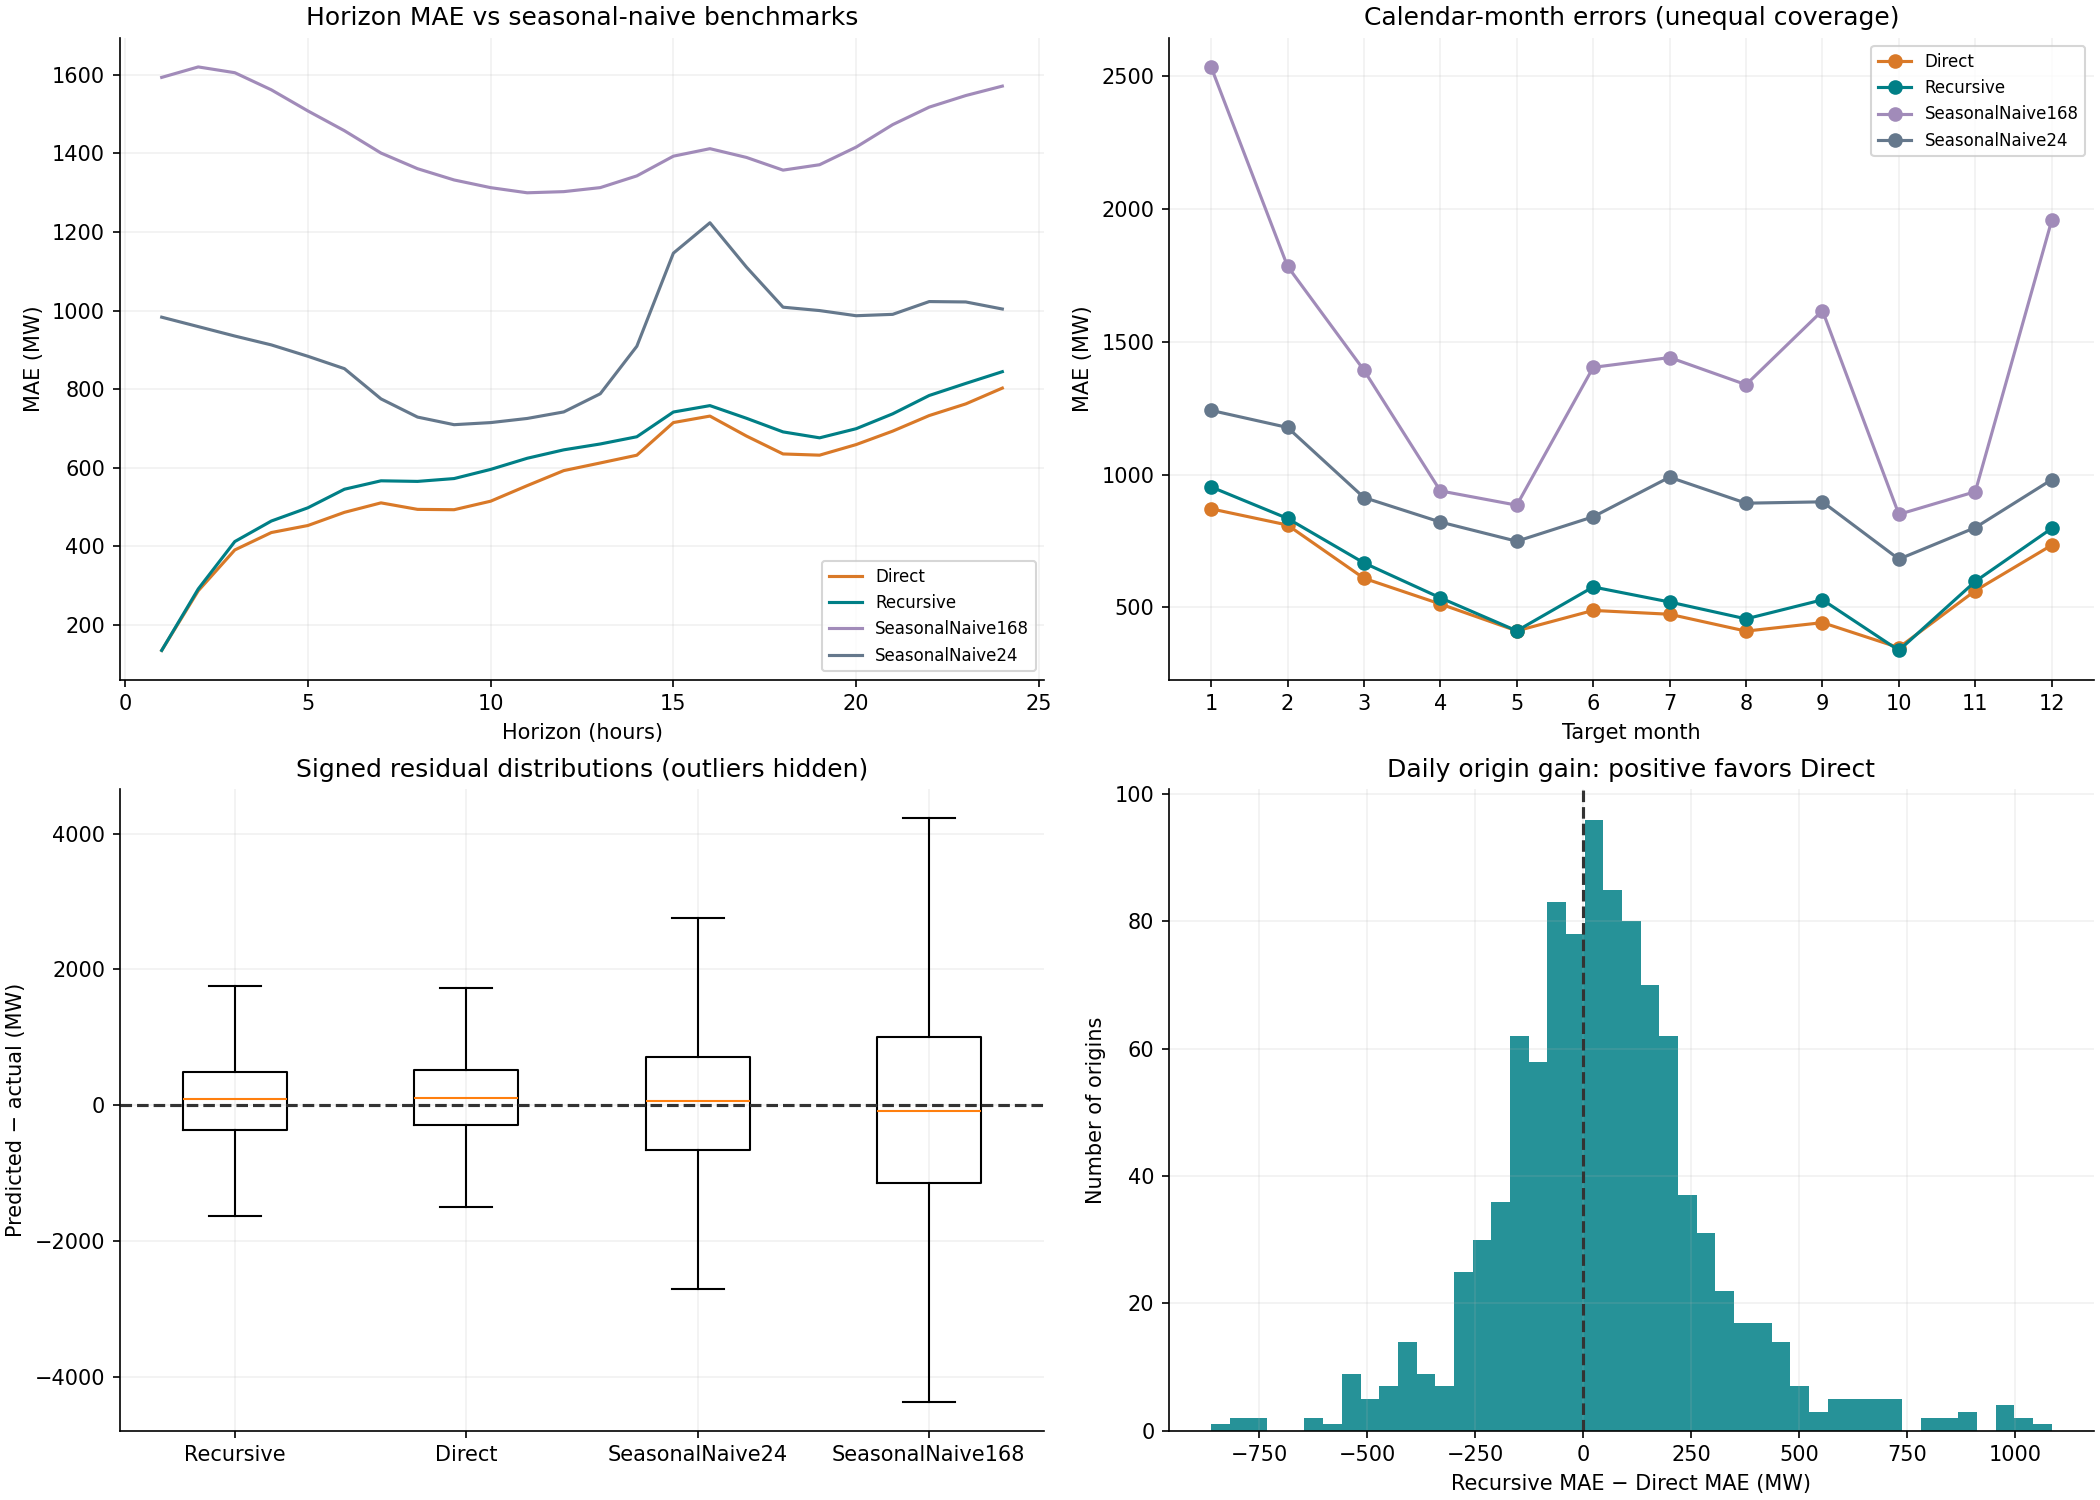

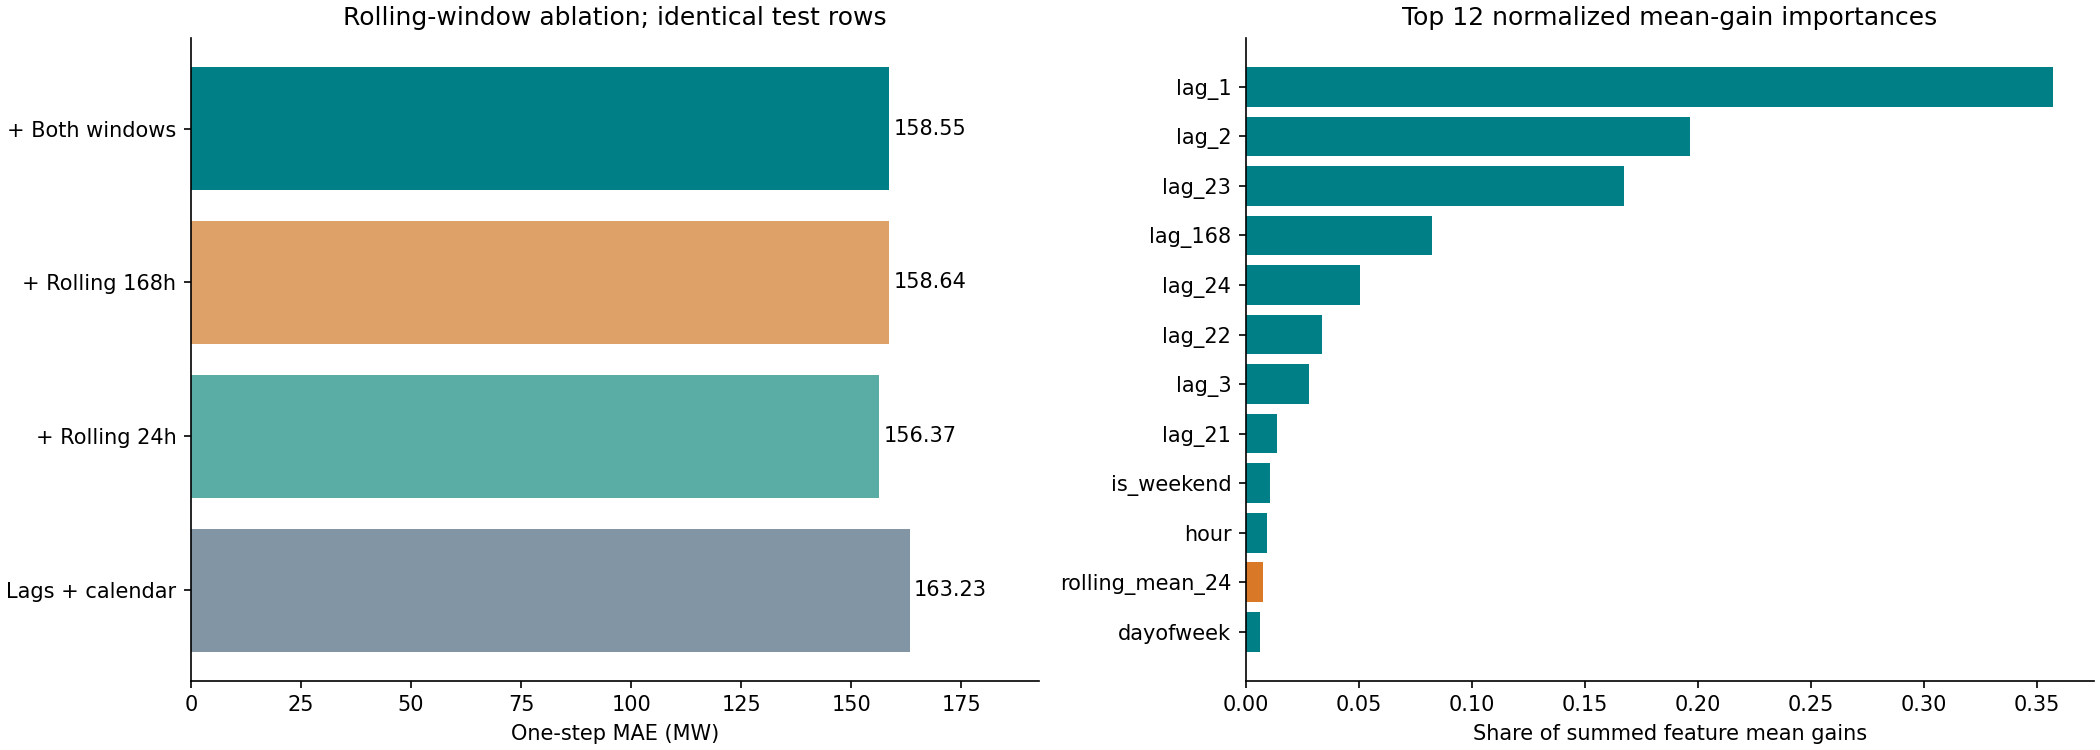

In [7]:
display(Image(filename=str(ROOT/'outputs/figures/cv04_diagnostic_dashboard.png')))
display(Image(filename=str(ROOT/'outputs/figures/cv04_ablation_importance.png')))

---

# CV04 — Phân tích chi tiết dành cho Trâm

**Chủ đề:** Đặc trưng rolling và dự báo phụ tải điện AEP trong 24 giờ tiếp theo.  
**Phần bài tập:** Nâng cao 1 và 2, thuộc `time-series-lab2`.  
**Ngày hoàn thiện phân tích:** 22/10/2026.  
**Cách đọc:** Phần 1–5 giải thích thiết kế; phần 6–14 phân tích số liệu; phần 15–20 hỗ trợ viết báo cáo, chạy lại và bảo vệ bài.

## 1. Kết quả chính và ý nghĩa thực tế

Trên cùng tập kiểm thử, thêm đủ bốn đặc trưng rolling làm MAE dự báo một bước giảm từ **163.23 xuống 158.55 MW**, tương đương **2.87%**.
Khi tách riêng cửa sổ, chỉ thêm rolling 24h đạt MAE **156.37 MW**, tốt hơn phương án thêm cả hai cửa sổ trong lần thực nghiệm này.
Điều đó cho thấy thêm nhiều đặc trưng không tự động tạo ra kết quả tốt hơn.

Với dự báo liên tục 24h, Direct đạt MAE **568.33 MW**, thấp hơn Recursive **7.41%**.
Tuy nhiên, Direct chỉ thắng **57.95%** số cửa sổ dự báo theo MAE của cả ngày.
Direct có bias dương **108.97 MW**, cao hơn Recursive **20.25 MW**; giảm sai số tuyệt đối và giảm thiên lệch trung bình là hai mục tiêu khác nhau.

So với đối chứng lấy cùng giờ hôm trước, Direct giảm MAE **38.37%**.
Đây là bằng chứng thực nghiệm có lợi cho mô hình học máy trên tập kiểm thử này, không phải cam kết về hiệu quả ở mọi giai đoạn tương lai.

## 2. Phạm vi, dữ liệu và các quyết định cần nói rõ

Phần CV04 đọc `train.csv` và `test.csv` của CV01. Mốc chia train/test được giữ nguyên; không trộn ngẫu nhiên và không thay đổi tệp của thành viên khác.
Theo bảng phân công chi tiết trên GitHub, CV04 gồm rolling, đánh giá tác động của rolling, dự báo Recursive và Direct, cùng phân tích sai số theo từng bước.

| Nội dung | Giá trị hoặc cách xử lý |
| --- | --- |
| Biến mục tiêu | AEP_MW, đơn vị MW |
| Train do CV01 cung cấp | 96,880 dòng; 2004-10-08 01:00:00 đến 2015-10-28 16:00:00 |
| Test do CV01 cung cấp | 24,221 dòng; 2015-10-28 17:00:00 đến 2018-08-03 00:00:00 |
| Giờ thiếu trong khoảng đọc | 27; train: 24, test: 3 |
| Train dùng cho rolling | 96,736 hàng sau bổ sung lưới giờ và bỏ warm-up |
| Đánh giá một bước | 24,221 target test quan sát thật |
| Đánh giá 24h | 1,006 cửa sổ × 24 = 24,144 target mỗi chiến lược |
| Thời gian phát hành dự báo | 16:00 theo timestamp trong CSV, dự báo từ 17:00 |
| Tần suất phát hành | Một lần sau mỗi 24h; không huấn luyện lại mô hình giữa các mốc |

**Phân biệt timestamp và múi giờ:** CSV sử dụng timestamp không gắn múi giờ. Không tự coi 16:00 là giờ Việt Nam hoặc chuyển thành UTC.
Việc bổ sung lưới giờ ở đây nhằm làm cho lag 24 tương ứng 24 vị trí giờ liên tục; chưa giải quyết đầy đủ ngữ nghĩa DST của khu vực cung cấp điện.
Bộ dữ liệu thô có 121.273 dòng và 4 timestamp trùng; phần trùng được xử lý ở CV01. CV04 kiểm tra đầu vào đã duy nhất trước khi chạy.

**Vì sao số hàng train giảm?** CV01 đã bỏ các hàng đầu chuỗi để tạo lag. CV04 tái tạo đặc trưng từ target trong các tệp đã xử lý, nên tiếp tục mất 168 giờ warm-up.
Sau bổ sung các giờ thiếu trong train rồi bỏ 168 giờ, số hàng còn lại là 96,736. Đây là lựa chọn triển khai để giữ hợp đồng đầu vào, không phải thay đổi tỷ lệ chia dữ liệu gốc.

**Vì sao số target 24h ít hơn test một bước?** Một cửa sổ chỉ được giữ nếu đủ 24 target thật. Cửa sổ chạm giờ thiếu và đoạn cuối chưa đủ 24h bị loại.
Do đó không được so sánh trực tiếp MAE một bước trên toàn bộ test với MAE h=1 trong tập cửa sổ như thể chúng dùng cùng mẫu.

## 3. Tạo rolling: từ công thức đến cách tránh leakage

Tại thời điểm cần dự báo $t$, thông tin quan sát chỉ được phép có đến $t-1$.
Với cửa sổ $w$, định nghĩa:

$$
\mu_{t,w}=\frac{1}{w}\sum_{i=1}^w y_{t-i},\qquad
s_{t,w}=\sqrt{\frac{1}{w-1}\sum_{i=1}^w(y_{t-i}-\mu_{t,w})^2}.
$$

Bốn đặc trưng được dùng là `rolling_mean_24`, `rolling_std_24`, `rolling_mean_168`, `rolling_std_168`.
Std dùng `ddof=1`, thống nhất giữa tính bằng pandas khi huấn luyện và bằng NumPy khi dự báo đệ quy.

```python
past = df['AEP_MW'].shift(1)
df['rolling_mean_24'] = past.rolling(24).mean()
df['rolling_std_24'] = past.rolling(24).std(ddof=1)
df['rolling_mean_168'] = past.rolling(168).mean()
df['rolling_std_168'] = past.rolling(168).std(ddof=1)
```

Ví dụ dự báo 10:00 ngày D: rolling 24h phải lấy từ 10:00 ngày D−1 đến 09:00 ngày D.
Nếu dùng `.rolling(24)` trực tiếp trên target, giá trị thực 10:00 sẽ nằm trong đầu vào của chính dự báo 10:00.
Kết quả có thể nhìn rất tốt nhưng không tái hiện được khi vận hành.

**Cách diễn giải:** Mean 24h tóm tắt mức nền gần nhất; std 24h mô tả biến động trong ngày gần nhất.
Cửa sổ 168h tóm tắt bối cảnh dài hơn, nhưng phản ứng chậm hơn khi mức nền thay đổi.
Rolling 168h trung bình toàn tuần; nó không tương đương lag 168h lấy đúng cùng giờ tuần trước.

**Mean ± std trên biểu đồ** là dải mô tả dao động của các quan sát quá khứ. Dải này không phải khoảng tin cậy hoặc khoảng dự báo của XGBoost.
Không có kiểm chứng độ phủ 68% hay 95% cho dải đó.

## 4. Huấn luyện và thiết kế đối chứng

Mỗi bộ đặc trưng dùng cùng các hàng train/test. Cơ sở có 25 lag (1–24, 168) và 7 biến lịch, tổng cộng 32 đặc trưng.
Thêm riêng rolling 24h hoặc 168h tạo 34 đặc trưng; thêm cả hai tạo 36 đặc trưng.

XGBoost dùng tối đa 1.000 cây, learning_rate=0.01, max_depth=5, subsample=0.8, colsample_bytree=0.8,
objective=`reg:squarederror`, `tree_method='hist'`, random_state=42, n_jobs=4.
Quy trình gồm: lấy 90% đầu train để fit, 10% cuối train làm validation, chọn số cây với early stopping 50 vòng,
sau đó huấn luyện lại trên toàn train bằng số cây đã chọn. Test chỉ dùng để báo cáo sai số.

**Điểm cần hiểu:** Early stopping là quy tắc dừng khi validation không cải thiện đủ lâu; không đảm bảo nó sẽ kích hoạt.
Trong cả bốn thí nghiệm rolling, số cây tốt nhất đều chạm mức 1.000. Vì vậy chưa thể khẳng định 1.000 là số cây tối ưu toàn cục.
Không tăng số cây chỉ vì nhìn test; một thí nghiệm mở rộng phải dùng validation hoặc TimeSeriesSplit thuộc phạm vi CV05.

Đối chứng tác động rolling ở đây tự huấn luyện mô hình của CV04. Không dùng checkpoint CV02 làm đối chứng trực tiếp,
vì checkpoint đó có thể dùng tập lag hoặc quy trình chọn cây khác. Việc tái tạo cùng lags và cùng hàng giúp so sánh có ý nghĩa hơn.

## 5. Recursive và Direct: đầu vào nào thực sự có sẵn?

### 5.1. Recursive: một mô hình, cập nhật dự báo vào lịch sử

Gọi $o$ là thời điểm quan sát cuối cùng. Bước đầu:

$$\hat y_{o+1}=f(y_o,y_{o-1},\ldots,\text{calendar}_{o+1},\text{rolling từ quá khứ}).$$

Ở bước hai, lag 1 trở thành $\hat y_{o+1}$, không phải $y_{o+1}$ thực tế.
Lặp đến bước 24. Mỗi vòng tính lại rolling từ lịch sử hỗn hợp: quan sát trước mốc $o$ và dự báo đã sinh sau mốc đó.
Các biến lịch được tính đúng timestamp tương lai vì lịch có thể biết trước.

```text
history = 168 quan sát trước mốc dự báo
for h = 1..24:
    X = tạo lag + rolling từ history; tạo biến lịch tại thời điểm o+h
    prediction[h] = model.predict(X)
    history = bỏ phần tử cũ nhất, thêm prediction[h]
```

Sai số ở bước đầu có thể làm thay đổi lag và rolling của bước tiếp theo; đây là cơ chế lan truyền sai số.
Ngoài ra mô hình được học với các lag thật nhưng khi dự báo xa lại nhận một phần lag dự báo: phân phối đầu vào có thể thay đổi.
Cơ chế đó giải thích nguy cơ suy giảm chất lượng, nhưng không chứng minh rằng MAE phải tăng ở mọi bước.

### 5.2. Direct: một mô hình riêng cho mỗi horizon

Huấn luyện 24 mô hình $f_h$. Tất cả dùng thông tin tại cùng mốc phát hành, rồi dự báo riêng target ở horizon h:

$$\hat y_{o+h}=f_h(X_{o+1}),\qquad h=1,\ldots,24.$$

Trong code, hàng đặc trưng tại timestamp $t=o+1$ dùng thông tin đến $t-1$; nhãn mô hình h là $y_{t+h-1}$.
Vì vậy `shift(-(h-1))` là cách ghép **nhãn tương lai** trong dữ liệu huấn luyện; nó không phải cho target tương lai vào đặc trưng.
Các nhãn vượt mốc test bị loại trước khi fit.

Ví dụ h=24, hàng X ở 17:00 ngày D phải ghép target 16:00 ngày D+1.
Nếu chỉ tách train/validation theo hàng mà không để gap, nhãn của những hàng cuối train có thể đi vào thời đoạn validation.
Triển khai chừa gap h−1 hàng ở ranh giới fit/validation để tránh điều này.

Direct không lấy $\hat y_{o+1}$ làm đầu vào để tạo $\hat y_{o+2}$ nên tránh kiểu phản hồi của Recursive.
Đổi lại cần 24 mô hình, mỗi horizon có ít hàng nhãn hợp lệ hơn ở cuối train, và các dự báo không bị ràng buộc phải liên tục giữa các horizon.
Trong phiên bản hiện tại, biến lịch của Direct là lịch tại hàng đặc trưng; mô hình h có horizon cố định nhưng chưa được cấp riêng lịch của timestamp target.
Đây là hướng mở rộng hợp lệ cho nghiên cứu sau, không phải điều chỉnh đã được kiểm chứng trong kết quả này.

### 5.3. Có được dùng test trước đó làm lịch sử không?

Có, nếu tại mốc phát hành mới các quan sát đó đã thực sự xảy ra. Đây là backtest với thông tin quá khứ được cập nhật.
Không được dùng target thực của 24 giờ đang dự báo để cập nhật nội bộ cửa sổ.
Mô hình trong backtest này giữ nguyên trọng số; cập nhật lịch sử khác với huấn luyện lại.

## 6. Chỉ số đánh giá và cách đọc đúng

Đặt $e_i=\hat y_i-y_i$; dấu dương nghĩa là dự báo cao hơn thực tế.

| Chỉ số | Câu hỏi trả lời | Lưu ý |
| --- | --- | --- |
| MAE | Sai lệch tuyệt đối trung bình bao nhiêu MW? | Dễ diễn giải, không cho biết dấu |
| RMSE | Sai số lớn bị phạt mạnh đến mức nào? | Nhạy với các trường hợp dự báo tệ |
| MAPE | Sai số tuyệt đối tương đối trung bình? | Nhạy với actual gần 0; code loại actual bằng 0 khỏi MAPE |
| WAPE | Tổng sai số tuyệt đối so với tổng tải thực tế? | Tỷ số tổng; không phải trung bình các MAPE |
| R² | Giải thích biến thiên target của mẫu đang chấm đến đâu? | Không phải phần trăm dự báo đúng |
| Bias | Có xu hướng dự báo thừa hoặc thiếu không? | Sai số dương/âm có thể triệt tiêu |
| P90/P95 absolute error | Đuôi sai số lớn đến mức nào? | Phân vị thực nghiệm; không phải khoảng dự báo |

$$MAE=\frac1n\sum_i|e_i|,\quad RMSE=\sqrt{\frac1n\sum_i e_i^2},\quad Bias=\frac1n\sum_i e_i.$$

Sai số từng horizon h được tính trên 1006 mốc dự báo.
Cumulative RMSE đến h gộp tất cả residual ở bước 1..h rồi lấy căn trung bình bình phương; không lấy trung bình các RMSE đã tính.
Dù dùng từ “tích lũy”, đây là sai số **gộp trung bình**, không phải tổng sai số ngày càng cộng dồn cơ học.

## 7. Thí nghiệm tách tác động từng cửa sổ rolling

| variant | n_features | MAE | RMSE | MAPE_pct | R2 | best_n_estimators |
| --- | --- | --- | --- | --- | --- | --- |
| lags_calendar | 32 | 163.235 | 212.102 | 1.127 | 0.992 | 1000 |
| plus_rolling_24 | 34 | 156.369 | 204.026 | 1.079 | 0.993 | 1000 |
| plus_rolling_168 | 34 | 158.644 | 206.827 | 1.095 | 0.993 | 1000 |
| plus_all_rolling | 36 | 158.548 | 206.720 | 1.094 | 0.993 | 1000 |

**Nhận xét 1:** Rolling 24h giảm MAE **4.21%** so với lags + calendar; kết quả tốt nhất trong bốn cấu hình.
**Nhận xét 2:** Rolling 168h vẫn có ích so với cơ sở, nhưng thêm cả hai cửa sổ không vượt riêng 24h.
Một diễn giải hợp lý là thông tin 24h bám bối cảnh ngắn hạn tốt hơn, còn rolling tuần có thể dư thừa với lag và lịch;
đây là diễn giải phù hợp với dữ liệu, chưa phải kết luận nhân quả.
**Nhận xét 3:** Thay đổi bộ đặc trưng cũng thay đổi quá trình chia cây và tập cột được lấy mẫu, nên mức cải thiện không thể quy hoàn toàn cho một đặc trưng riêng lẻ.

Không chuyển kết quả tốt của rolling 24h trong bài toán một bước thành khẳng định nó chắc chắn tốt nhất cho Recursive 24h.
Dự báo nhiều bước hiện vẫn dùng đủ bốn rolling theo thiết kế đã công bố; muốn lựa chọn cửa sổ cho nhiều bước phải đánh giá trên validation nhiều bước riêng.

![Ablation và importance](../outputs/figures/cv04_ablation_importance.png)

### 7.1. Mức cải thiện có ổn định qua các ngày không?

| candidate | MAE_reduction_MW | CI95_low_MW | CI95_high_MW | candidate_win_rate_pct |
| --- | --- | --- | --- | --- |
| plus_rolling_24 | 6.817 | 6.156 | 7.470 | 78.140 |
| plus_rolling_168 | 4.604 | 4.001 | 5.222 | 72.898 |
| plus_all_rolling | 4.682 | 3.979 | 5.364 | 71.316 |

Bảng trên dùng loss trung bình của từng ngày lịch rồi resample các block 7 ngày theo thứ tự; 2.000 lần, seed=42.
Các khoảng percentile 95% nằm phía dương trong lần chạy này: kết quả ủng hộ việc bổ sung rolling khi giữ nguyên mô hình và mẫu kiểm thử.
Đây là bất định của **loss quan sát trên test với mô hình đã fit**; không bao gồm thay đổi do huấn luyện lại mô hình, lựa chọn đặc trưng sau nhìn test hoặc thay đổi phân phối tương lai.

Lưu ý mẫu số: bootstrap rolling cho trọng số bằng nhau cho từng ngày lịch, còn MAE toàn test cho trọng số bằng nhau cho từng giờ.
Các ngày đầu/cuối không đủ 24 giờ làm hai mức giảm MAE hơi khác nhau. Không thay số ở bảng này vào bảng MAE toàn test.

### 7.2. Importance nhỏ có nghĩa rolling vô ích không?

| feature | normalized_gain | group |
| --- | --- | --- |
| lag_1 | 0.357 | lags |
| lag_2 | 0.197 | lags |
| lag_23 | 0.168 | lags |
| lag_168 | 0.082 | lags |
| lag_24 | 0.050 | lags |
| lag_22 | 0.034 | lags |
| lag_3 | 0.028 | lags |
| lag_21 | 0.014 | lags |
| is_weekend | 0.011 | calendar |
| hour | 0.009 | calendar |
| rolling_mean_24 | 0.008 | rolling |
| dayofweek | 0.006 | calendar |

Trong mô hình có đủ rolling, tổng normalized mean-gain của nhóm rolling là **1.13%**, nhóm lags **96.01%**, nhóm lịch **2.87%**.
Đây là chuẩn hóa tổng **gain trung bình của từng đặc trưng**, không phải tỷ lệ nguyên nhân tạo ra phụ tải hoặc tỷ lệ đóng góp chính xác vào dự báo.
Vì các lag và rolling tương quan mạnh, mô hình có thể dùng một biến đại diện cho nhiều thông tin liên quan.
Ablation trả lời “bỏ/thêm nhóm này thì sai số thay đổi ra sao”; importance trả lời “mô hình hiện tại chia cây bằng biến nào”. Hai câu hỏi khác nhau.

## 8. So sánh 24 giờ với các đối chứng đơn giản

Đối chứng SeasonalNaive24 lấy đúng cùng giờ hôm trước: $\hat y_{o+h}=y_{o+h-24}$.
SeasonalNaive168 lấy cùng giờ tuần trước: $\hat y_{o+h}=y_{o+h-168}$.
Với h≤24, tất cả giá trị đó có sẵn tại hoặc trước mốc $o$; không có leakage.
Hai đối chứng dùng đúng cùng timestamp và actual với hai mô hình học máy.

| strategy | n | MAE | RMSE | MAPE_pct | WAPE_pct | R2 | Bias_MW |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Direct | 24144 | 568.330 | 772.732 | 3.911 | 3.861 | 0.900 | 108.967 |
| Recursive | 24144 | 613.825 | 847.288 | 4.160 | 4.170 | 0.880 | 20.252 |
| SeasonalNaive168 | 24144 | 1,435.360 | 1,909.357 | 9.629 | 9.751 | 0.391 | -16.613 |
| SeasonalNaive24 | 24144 | 922.171 | 1,222.532 | 6.250 | 6.265 | 0.750 | -3.758 |

Direct giảm MAE **7.41%** và RMSE **8.80%** so với Recursive.
Hai mô hình học máy đều tốt hơn hai seasonal-naive trên chỉ số gộp của mẫu này.
SeasonalNaive168 kém SeasonalNaive24 dù dữ liệu có chu kỳ tuần: tồn tại mùa vụ không có nghĩa lặp nguyên giá trị tuần trước là đủ.
Mức nền, loại ngày, biến động tải và yếu tố chưa quan sát có thể thay đổi; kết quả không xác định nguyên nhân nào là chính.

Không so sánh MAE 158,55 MW một bước với 568,33 MW Direct để kết luận Direct kém:
bài toán một bước luôn được nhận quan sát mới trước mỗi giờ, còn Direct phải phát hành cả 24 giờ chỉ từ thông tin ở đầu cửa sổ.

## 9. Sai số theo từng horizon: đủ cả 24 bước

| horizon | Recursive | Direct | SeasonalNaive24 | SeasonalNaive168 | Direct_gain_pct |
| --- | --- | --- | --- | --- | --- |
| 1 | 135.622 | 135.622 | 983.044 | 1,592.804 | 0.000 |
| 2 | 291.876 | 287.330 | 959.078 | 1,619.443 | 1.558 |
| 3 | 412.434 | 391.122 | 935.086 | 1,604.752 | 5.167 |
| 4 | 464.669 | 435.360 | 912.518 | 1,561.164 | 6.308 |
| 5 | 498.299 | 453.255 | 883.592 | 1,507.540 | 9.039 |
| 6 | 545.507 | 486.765 | 852.093 | 1,457.213 | 10.768 |
| 7 | 566.917 | 510.830 | 775.259 | 1,400.417 | 9.893 |
| 8 | 565.424 | 494.301 | 728.975 | 1,360.637 | 12.579 |
| 9 | 572.638 | 493.411 | 709.651 | 1,331.984 | 13.836 |
| 10 | 595.915 | 515.080 | 714.956 | 1,312.450 | 13.565 |
| 11 | 624.238 | 554.626 | 725.472 | 1,299.358 | 11.152 |
| 12 | 645.679 | 592.859 | 742.083 | 1,302.292 | 8.181 |
| 13 | 660.597 | 612.319 | 788.325 | 1,312.537 | 7.308 |
| 14 | 678.952 | 632.032 | 909.152 | 1,342.345 | 6.911 |
| 15 | 741.846 | 715.036 | 1,145.858 | 1,392.489 | 3.614 |
| 16 | 758.144 | 731.519 | 1,223.127 | 1,411.546 | 3.512 |
| 17 | 725.927 | 680.721 | 1,110.265 | 1,389.261 | 6.227 |
| 18 | 691.313 | 635.201 | 1,008.467 | 1,356.977 | 8.117 |
| 19 | 676.192 | 632.135 | 999.841 | 1,370.718 | 6.515 |
| 20 | 699.409 | 659.039 | 986.734 | 1,415.496 | 5.772 |
| 21 | 737.238 | 693.255 | 990.236 | 1,472.696 | 5.966 |
| 22 | 783.916 | 732.879 | 1,022.736 | 1,517.191 | 6.510 |
| 23 | 814.595 | 762.524 | 1,021.757 | 1,546.665 | 6.392 |
| 24 | 844.448 | 802.703 | 1,003.799 | 1,570.671 | 4.943 |

Recursive và Direct h=1 giống nhau vì cùng cấu trúc đặc trưng và cùng bài toán target đầu tiên.
Về phía cuối chân trời, h=24 Recursive có MAE **844,45 MW**, Direct **802,70 MW**.
Cần nhìn cả 24 bước: có những đoạn đường MAE giảm khi h tăng, phù hợp với thay đổi độ khó theo giờ trong ngày.

### 9.1. Hạn chế quan trọng: horizon đi cùng giờ mục tiêu

Tất cả mốc phát hành hiện tại là 16:00. Vì thế h=1 luôn là 17:00, h=8 luôn là 00:00, h=16 luôn là 08:00 và h=24 luôn là 16:00 hôm sau.
Khi sai số cao ở h=16, ta đồng thời đang nhìn một horizon xa và giờ 08:00; không thể tách hai ảnh hưởng chỉ bằng đường MAE này.
Kết luận có căn cứ là “sai số thay đổi theo horizon trong lịch phát hành cố định này”, không phải “mọi phần tăng đều do tích lũy sai số”.
Muốn tách tốt hơn cần chạy thêm nhiều giờ phát hành, giữ cùng các horizon và báo cáo theo cả horizon lẫn giờ mục tiêu.
Đây là giới hạn thiết kế đang được nêu rõ; chưa có thí nghiệm nhiều giờ phát hành trong các bảng hiện tại.

### 9.2. Gộp horizon thành bốn nhóm dễ trình bày

| strategy | horizon_band | n | MAE | RMSE | MAPE_pct | Bias_MW |
| --- | --- | --- | --- | --- | --- | --- |
| Direct | 01-06 | 6036 | 364.909 | 492.568 | 2.335 | 11.703 |
| Direct | 07-12 | 6036 | 526.851 | 698.371 | 3.951 | 88.620 |
| Direct | 13-18 | 6036 | 667.805 | 902.626 | 4.741 | 152.139 |
| Direct | 19-24 | 6036 | 713.756 | 918.358 | 4.616 | 183.407 |
| Recursive | 01-06 | 6036 | 391.401 | 535.516 | 2.501 | 15.291 |
| Recursive | 07-12 | 6036 | 595.135 | 805.288 | 4.389 | 30.885 |
| Recursive | 13-18 | 6036 | 709.463 | 982.893 | 4.913 | -3.201 |
| Recursive | 19-24 | 6036 | 759.299 | 985.011 | 4.838 | 38.034 |

Các nhóm cùng có 6.036 target, thuận tiện cho so sánh trong lịch phát hành này.
Nhóm cuối khó hơn nhóm đầu về MAE, nhưng vẫn cần giữ lưu ý horizon/giờ mục tiêu ở trên.

![Biểu đồ chính](../outputs/figures/cv04_multistep_forecast.png)

## 10. Phân tích theo mùa, năm và ngày trong tuần

### 10.1. Theo tháng trong năm

| month | Direct | Recursive | Direct_gain_pct |
| --- | --- | --- | --- |
| 1 | 871.158 | 953.633 | 8.649 |
| 2 | 810.187 | 835.072 | 2.980 |
| 3 | 609.673 | 667.597 | 8.677 |
| 4 | 512.871 | 536.094 | 4.332 |
| 5 | 411.656 | 411.778 | 0.030 |
| 6 | 488.678 | 577.007 | 15.308 |
| 7 | 474.237 | 520.344 | 8.861 |
| 8 | 410.723 | 456.861 | 10.099 |
| 9 | 442.720 | 528.681 | 16.260 |
| 10 | 348.747 | 338.117 | -3.144 |
| 11 | 562.986 | 597.955 | 5.848 |
| 12 | 734.300 | 797.522 | 7.927 |

Tháng 1 và 2 có MAE cao ở cả hai mô hình, còn tháng 10 có MAE thấp hơn trong test này.
Direct không thắng trong mọi tháng; các giá trị `Direct_gain_pct` âm chỉ ra tháng Recursive tốt hơn.
Các tháng có số giờ và số năm bao phủ khác nhau, nên không nên xếp hạng độ khó mùa vụ mà bỏ qua `n` trong tệp chi tiết.
Không có nhiệt độ hoặc ngày lễ trong mô hình: liên hệ sai số mùa đông với thời tiết là giả thuyết hợp lý để nghiên cứu, chưa được kiểm chứng bằng biến khí tượng.

![Tháng và horizon](../outputs/figures/cv04_month_horizon_heatmap.png)

### 10.2. Theo năm kiểm thử

| strategy | year | n | MAE | RMSE | MAPE_pct | Bias_MW |
| --- | --- | --- | --- | --- | --- | --- |
| Direct | 2015 | 1543 | 628.275 | 822.267 | 4.783 | 270.848 |
| Direct | 2016 | 8760 | 540.436 | 744.161 | 3.717 | 91.907 |
| Direct | 2017 | 8736 | 562.541 | 771.219 | 3.903 | 124.057 |
| Direct | 2018 | 5105 | 607.985 | 807.220 | 3.992 | 63.491 |
| Recursive | 2015 | 1543 | 641.915 | 843.128 | 4.787 | 107.103 |
| Recursive | 2016 | 8760 | 597.142 | 833.717 | 4.053 | 16.188 |
| Recursive | 2017 | 8736 | 589.420 | 817.790 | 4.035 | 19.077 |
| Recursive | 2018 | 5105 | 675.726 | 918.273 | 4.369 | 2.986 |

2015 chỉ gồm cuối năm; 2018 chỉ gồm đầu năm đến đầu tháng 8. Vì vậy khác biệt giữa các năm còn lẫn khác biệt mùa được bao phủ.
Không suy ra “model drift” chỉ từ MAE 2018 tăng; cần đánh giá các giai đoạn cùng mùa và kiểm tra thay đổi đặc trưng/target trước.

### 10.3. Ngày làm việc và cuối tuần

| strategy | day_type | n | MAE | MAPE_pct | Bias_MW |
| --- | --- | --- | --- | --- | --- |
| Direct | weekday | 17304 | 567.526 | 3.812 | 112.228 |
| Direct | weekend | 6840 | 570.364 | 4.161 | 100.720 |
| Recursive | weekday | 17304 | 611.059 | 4.043 | 33.484 |
| Recursive | weekend | 6840 | 620.822 | 4.458 | -13.221 |

Cuối tuần có MAPE cao hơn dù chênh lệch MAE có thể nhỏ, vì tải nền và mẫu số của sai số tương đối khác nhau.
Đây là cách đọc chung cả sai số tuyệt đối và tương đối, tránh chỉ chọn chỉ số có lợi.
Phân nhóm được xác định từ **ngày của target**, không phải ngày của mốc phát hành.
Ngày lễ có thể rơi vào weekday; biến cuối tuần chưa đại diện đầy đủ cho lịch vận hành.

## 11. Phụ tải thấp/cao: có bỏ sót các đỉnh quan trọng không?

Ngưỡng được lấy từ train: Q25=13,825 MW và Q75=17,396 MW.
Các target test được phân thành low (≤Q25), middle (Q25..Q75), high (>Q75).
Việc phân nhóm theo actual chỉ phục vụ kiểm toán sau khi có kết quả; không dùng actual tương lai để định tuyến mô hình lúc dự báo.

| strategy | load_regime | n | MAE | MAPE_pct | Bias_MW |
| --- | --- | --- | --- | --- | --- |
| Direct | low | 9163 | 525.844 | 4.290 | 362.545 |
| Direct | middle | 11353 | 561.963 | 3.681 | 83.053 |
| Direct | high | 3628 | 695.559 | 3.671 | -450.383 |
| Recursive | low | 9163 | 509.980 | 4.136 | 267.969 |
| Recursive | middle | 11353 | 630.563 | 4.116 | -12.329 |
| Recursive | high | 3628 | 823.720 | 4.360 | -503.434 |

Ở nhóm high, cả hai mô hình có bias âm: có xu hướng đánh giá thấp các mức tải lớn.
Direct giảm MAE nhóm high từ **823,72 xuống 695,56 MW**, nhưng bias vẫn khoảng **−450,38 MW**.
Trong nhóm low, Direct có MAE lớn hơn Recursive và bias dương mạnh hơn.
Điều này phù hợp với khuynh hướng co dự báo về các mức trung tâm; đây là mô tả kết quả, chưa xác định cơ chế duy nhất.

Nếu mục tiêu vận hành ưu tiên tránh thiếu dự báo ở đỉnh, chỉ tối ưu MAE gộp chưa đủ.
Có thể nghiên cứu loss bất đối xứng hoặc quantile forecasting, nhưng cần thiết kế validation và kiểm tra calibration mới; chưa có kết quả cho các phương án đó trong bài này.
R² của từng nhóm không nên so trực tiếp với R² toàn bộ test: nhóm tải hẹp làm phương sai actual thay đổi.

## 12. Bias, đuôi sai số và các trường hợp khó

| strategy | Bias_MW | Median_AE | P90_AE | P95_AE | Max_AE |
| --- | --- | --- | --- | --- | --- |
| Direct | 108.967 | 414.257 | 1,287.377 | 1,659.112 | 3,923.219 |
| Recursive | 20.252 | 435.806 | 1,421.390 | 1,812.569 | 4,869.238 |
| SeasonalNaive168 | -16.613 | 1,084.000 | 3,260.000 | 3,975.850 | 8,276.000 |
| SeasonalNaive24 | -3.758 | 688.500 | 2,061.700 | 2,547.850 | 7,656.000 |

Direct có P95 absolute error khoảng **1659 MW**: khoảng 95% sai số tuyệt đối quan sát nằm dưới mức này, còn khoảng 5% lớn hơn.
Không diễn giải thành “lần dự báo mới có khoảng tin cậy 95% ±1659 MW”, vì đó là phân vị test gộp,
không được hiệu chỉnh theo horizon, mức tải hay phụ thuộc thời gian.

Bias gộp Recursive gần 20 MW trong khi MAE hơn 600 MW: sai số dương và âm triệt tiêu nhau.
Do đó “bias thấp” không đồng nghĩa “dự báo sát”. Direct giảm MAE/RMSE nhưng tăng bias dương; đây là đánh đổi cần báo cáo trung thực.

Ví dụ sai số giờ lớn nhất của Recursive trong test: **2016-01-11 08:00:00**, h=16,
actual=20,610 MW, predicted=15,741 MW, error=-4,869 MW.
Tệp `cv04_largest_errors.csv` giữ 10 giờ sai số lớn nhất của mỗi chiến lược để kiểm tra lại.

Ba ví dụ dưới đây được chọn theo quy tắc công bố: cửa sổ hợp lệ đầu tiên, cửa sổ ở giữa thứ hạng MAE Recursive,
và cửa sổ có MAE Recursive lớn nhất. Chúng giúp minh họa cơ chế; không đại diện ngẫu nhiên cho mọi ngày,
và cách chọn theo Recursive có thể ảnh hưởng cảm nhận khi so với Direct.

![Các trường hợp điển hình](../outputs/figures/cv04_case_studies.png)

## 13. Direct tốt hơn có đủ đáng tin trên mẫu kiểm thử này không?

Cần so **theo cặp**: cùng một mốc dự báo, tính MAE Recursive trừ MAE Direct của 24 giờ đó.
Nếu dương, Direct tốt hơn ở mốc đó. Không bootstrap riêng hai mẫu làm mất cấu trúc ghép cặp.

| block_length | repetitions | MAE_reduction_MW | CI95_low_MW | CI95_high_MW | candidate_win_rate_pct |
| --- | --- | --- | --- | --- | --- |
| 1 | 2000 | 45.495 | 30.073 | 61.113 | 57.952 |
| 7 | 2000 | 45.495 | 27.453 | 63.850 | 57.952 |
| 14 | 2000 | 45.495 | 26.358 | 63.025 | 57.952 |

Với block 7 mốc, mức giảm MAE trung bình là **45.49 MW** và khoảng percentile 95% là
**[27.45; 63.85] MW**. Kết quả vẫn phía dương khi đổi block 1 hoặc 14.
Điều đó ủng hộ ưu thế trung bình của Direct trên tập forecast đã có.

Tự tương quan lag 1 của MAE theo mốc là khoảng 0.318 với Recursive
và 0.292 với Direct.
Resample từng giờ độc lập sẽ bỏ qua phụ thuộc thời gian; bài này dùng circular blocks theo thứ tự các mốc hợp lệ.
Các mốc chạm giờ thiếu đã bị loại nên một block “7 mốc” có thể không luôn đúng 7 ngày lịch liên tiếp.
Kết quả là xấp xỉ bootstrap của loss trong mẫu, không phải một chứng minh đảm bảo bao phủ dưới mọi cấu trúc phụ thuộc.

Khoảng trên **không** phản ánh bất định do lấy lại mẫu train/fit lại, chọn mô hình sau nhiều so sánh, hoặc thay đổi môi trường tương lai.
Đây là phân tích khám phá; không công bố p-value hay khẳng định thắng tuyệt đối ở mức ý nghĩa cố định.
Tỷ lệ thắng chỉ khoảng 57.95% cũng cho thấy ưu thế trung bình không chuyển thành thắng mọi cửa sổ.

![Dashboard chẩn đoán](../outputs/figures/cv04_diagnostic_dashboard.png)

## 14. Giới hạn và hướng phát triển có thứ tự ưu tiên

1. **Một lần chia thời gian:** Chưa có bằng chứng lặp lại qua nhiều giai đoạn train/test độc lập. Có thể mở rộng bằng rolling-origin validation, giữ một test cuối chưa dùng.
2. **Giờ phát hành cố định:** Cần kiểm tra nhiều giờ phát hành để tách horizon và giờ mục tiêu; đây là hạn chế có ảnh hưởng trực tiếp đến diễn giải tích lũy sai số.
3. **Ngân sách cây bị chạm:** Bốn ablation đều đạt 1.000 cây. Nên kiểm tra ngân sách lớn hơn trên validation; CV04 chưa thực hiện tuning rộng thay CV05.
4. **Giờ thiếu và DST:** Forward-fill bảo toàn chiều thời gian nhưng có thể tạo đoạn tải phẳng. Cần metadata múi giờ và sensitivity analysis với cách xử lý khác.
5. **Thiếu ngoại sinh:** Chưa có thời tiết, ngày lễ và thông tin vận hành. Chưa thể gán sai số tháng/đỉnh cho một nguyên nhân cụ thể.
6. **Chỉ dự báo điểm:** Chưa tạo khoảng dự báo có calibration. Dải rolling std, P95 absolute error và bootstrap CI của chênh lệch MAE là ba khái niệm khác nhau.
7. **Tương quan đặc trưng:** Gain importance không phải bằng chứng nhân quả. Ablation một seed/holdout không bao quát mọi bất định mô hình.
8. **Direct và chi phí:** Cần 24 mô hình ở giai đoạn học. Chưa đo thời gian huấn luyện Direct toàn bộ bằng một benchmark kiểm soát tài nguyên, nên không ghi một hệ số tốc độ chính xác.
9. **Rủi ro thiếu dự báo đỉnh:** Nếu bài toán vận hành ưu tiên đỉnh, nên đánh giá thêm loss bất đối xứng, recall sự kiện vượt ngưỡng hoặc quantile loss bằng validation thích hợp.

## 15. Đoạn nhận xét có thể ghép vào báo cáo nhóm

> Trong phần nâng cao, nhóm tạo bốn đặc trưng rolling mean/std với cửa sổ 24 và 168 giờ trên chuỗi đã trễ một bước nhằm tránh rò rỉ dữ liệu. Trên cùng các hàng kiểm thử, thêm cả hai cửa sổ làm MAE một bước giảm từ 163.23 xuống 158.55 MW, tương đương 2.87%. Thí nghiệm tách cửa sổ cho thấy chỉ bổ sung rolling 24h đạt MAE 156.37 MW, phản ánh việc tăng số đặc trưng không luôn cải thiện chất lượng. Với 1006 mốc dự báo, mỗi mốc 24 giờ, chiến lược Direct đạt MAE 568.33 MW và RMSE 772.73 MW, so với 613.82 MW và 847.29 MW của Recursive. Mức giảm MAE trung bình là 7.41%; Direct tốt hơn ở khoảng 57.95% cửa sổ. Sai số được phân tích thêm theo horizon, mùa, loại ngày và mức tải. Cả hai mô hình có xu hướng thiếu dự báo ở nhóm tải cao. Do giờ phát hành cố định 16:00, đường sai số theo horizon đồng thời chịu ảnh hưởng của giờ mục tiêu; vì vậy kết quả cho thấy nguy cơ suy giảm dự báo xa nhưng không tách riêng được toàn bộ tác động của tích lũy sai số. Kết luận chỉ áp dụng cho cấu hình và giai đoạn kiểm thử đã đánh giá.

## 16. Gợi ý trình bày miệng trong khoảng 4–5 phút

**Phút 1 — Nêu bài toán:** “Em phụ trách rolling features và dự báo 24 giờ. Điều quan trọng là mô phỏng đúng thông tin có sẵn khi dự báo, không lấy dữ liệu của tương lai.”

**Phút 2 — Giải thích rolling:** Dùng ví dụ dự báo 10:00 và cửa sổ quá khứ kết thúc 09:00. Chỉ ra `.shift(1)`, ý nghĩa mean/std, rồi đưa ablation 24h/168h.

**Phút 3 — Giải thích hai chiến lược:** Recursive dùng dự báo trước làm lag tiếp theo; Direct học một mô hình cho từng horizon. Nêu gap nhãn và việc không sử dụng test để early stopping.

**Phút 4 — Đọc kết quả:** MAE một bước giảm 2.87% với đủ rolling; Direct giảm MAE nhiều bước 7.41%; so với naive hôm qua giảm 38.37%.
Chỉ vào nhóm tải cao và nói rõ vẫn tồn tại thiếu dự báo đỉnh.

**Phút 5 — Giới hạn:** Horizon gắn với giờ mục tiêu; Direct không thắng mọi cửa sổ; chưa có ngoại sinh hay khoảng dự báo đã hiệu chỉnh.
Kết thúc bằng lựa chọn có căn cứ cho **mẫu hiện tại**, không tuyên bố mô hình tốt nhất trong mọi bối cảnh.

## 17. Câu hỏi bảo vệ và cách trả lời

**Vì sao rolling cần shift(1)?** Vì target tại t chưa được quan sát lúc dự báo t. Rolling không shift có thể chứa chính target cần đoán.

**Tại sao rolling 24h tốt hơn thêm cả 168h?** Thực nghiệm cho thấy vậy trên cấu hình này. Thông tin tuần có thể dư thừa hoặc làm thay đổi cách chia cây; chưa đủ để kết luận cửa sổ tuần luôn xấu.

**Rolling mean 24h có khác lag 24h không?** Có. Một biến tổng hợp 24 giá trị gần nhất; biến kia lấy một giá trị ở đúng vị trí trễ 24 giờ.

**Trong dự báo đệ quy, lấy rolling đã tính sẵn từ toàn test được không?** Không. Từ h=2, rolling đó có thể chứa actual trong cửa sổ đang dự báo; phải tính lại từ lịch sử đã cập nhật bằng dự báo.

**Vì sao có thể dùng test của hôm trước?** Vì khi phát hành dự báo hôm nay, các giá trị hôm trước đã là quá khứ quan sát được. Không được dùng test trong chính khoảng tương lai chưa xảy ra.

**Direct có leakage vì shift âm không?** Shift âm dùng để ghép nhãn huấn luyện; leakage chỉ xảy ra nếu target tương lai vào X hoặc nhãn vượt ranh giới không bị loại. Code chỉ shift nhãn và có gap khi validation.

**Tại sao h=1 có MAE 135,62 MW mà một bước toàn test là 158,55 MW?** H=1 của backtest chỉ lấy 1.006 target ở 17:00 trong cửa sổ hợp lệ; một bước toàn test lấy 24.221 giờ. Khác mẫu nên khác MAE.

**MAE tăng theo horizon có chứng minh tích lũy sai số?** Nó phù hợp với cơ chế phản hồi, nhưng chưa cô lập tác động vì mỗi horizon gắn với một giờ mục tiêu. Sai số không buộc tăng đơn điệu.

**R²=0,90 có phải chính xác 90% không?** Không. Đây là mức giải thích phương sai target so với dự báo bằng trung bình trong mẫu đánh giá, không phải tỷ lệ dự báo nằm trong một ngưỡng sai số.

**Bias Direct cao hơn nhưng MAE thấp hơn có mâu thuẫn không?** Không. Bias giữ dấu, MAE lấy trị tuyệt đối. Một mô hình có thể giảm độ lớn sai số nhưng vẫn thiên về phía dự báo thừa.

**Bootstrap 95% có bảo đảm dự báo tương lai không?** Không. Đây là khoảng xấp xỉ cho chênh lệch loss trung bình trên các forecast đã tạo, với giả định của cách lấy block; không phải khoảng dự báo cho một giờ tương lai.

**Vì sao không đổi sang cấu hình tốt nhất trên test rồi báo kết quả?** Như vậy dùng test cho lựa chọn mô hình. Cần chọn bằng validation độc lập và đánh giá cuối trên test chưa dùng; bài này giữ các thí nghiệm là phân tích khám phá.

## 18. Hướng dẫn chạy lại và đọc các tệp

Tại thư mục `time-series-lab2`:

```bash
python -m pip install -r requirements.txt
python src/cv04_rolling_and_multistep.py
python src/cv04_detailed_analysis.py
python src/cv04_build_analysis_report.py
python -m unittest discover -s tests -v
```

Lần đầu chạy script chính huấn luyện cả Recursive và 24 Direct; script phân tích huấn luyện bốn ablation để kiểm toán riêng các cửa sổ.
Thời gian fit ablation đo bằng `perf_counter` trong lần chạy, bao gồm chọn số cây và refit; kết quả phụ thuộc máy, tải hệ thống, cache và số luồng.
Không dùng thời gian vài giây đó như benchmark phần cứng tổng quát.
Nếu macOS báo thiếu OpenMP, cần runtime `libomp` phù hợp. Môi trường kiểm chứng lần này dùng XGBoost 2.1.4.

| Nhóm tệp | Mục đích |
| --- | --- |
| `cv04_ablation_summary.csv`, `cv04_one_step_predictions.csv` | Bốn cấu hình rolling, dự báo từng target một bước |
| `cv04_ablation_validation_history.csv` | Validation RMSE qua từng vòng boosting |
| `cv04_rolling_model_importance.csv`, `cv04_train_feature_correlations.csv` | Gain importance và tương quan tính trên train |
| `cv04_strategy_summary.csv` | So sánh Recursive, Direct và hai seasonal-naive |
| `cv04_error_by_horizon.csv`, `cv04_error_by_horizon_band.csv` | Sai số từng giờ và từng nhóm 6 giờ |
| `cv04_error_by_month.csv`, `cv04_error_by_year.csv` | Sai số theo mùa/năm, kèm số mẫu |
| `cv04_error_by_hour.csv`, `cv04_error_by_day_type.csv` | Giờ mục tiêu và weekday/weekend |
| `cv04_error_by_load_regime.csv` | Sai số theo nhóm tải, ngưỡng từ train |
| `cv04_origin_mae.csv`, `cv04_origin_diagnostics.csv` | Loss và bias theo từng mốc 24h |
| `cv04_largest_errors.csv` | Các giờ sai số lớn nhất để truy nguyên |
| `cv04_rolling_bootstrap.csv`, `cv04_strategy_bootstrap.csv` | Khoảng bootstrap và độ nhạy block 1/7/14 |
| `cv04_missing_hours_audit.csv`, `cv04_analysis_metadata.json` | Giờ thiếu, ngưỡng phân nhóm, ánh xạ horizon–giờ |
| `docs/CV04_PHAN_TICH_CHI_TIET.md` | Báo cáo này, có thể ghép nội dung vào CV06 |
| `notebooks/cv04_tram_analyst.ipynb` | Notebook đọc kết quả và minh họa lại các phân tích |

Tất cả CSV ở bảng trên nằm trong `outputs/tables/`. Các hình được lưu trong `outputs/figures/`, DPI 150.
Dự báo từng mốc trong `cv04_multistep_predictions.csv` và `cv04_direct_predictions.csv` là căn cứ để tính lại metrics.
Notebook đọc các đầu ra đã chạy, không tự huấn luyện lại khi mở; muốn thay dữ liệu phải chạy lại hai script trước.

## 19. Các kiểm chứng cần giữ khi bàn giao

- Kiểm tra target hiện tại/tương lai không làm thay đổi feature ở thời điểm đang xét.
- Dùng mô hình giả để kiểm tra h=2 lấy prediction h=1 làm lag, rolling được cập nhật và giờ lịch qua nửa đêm đúng.
- Từ chối chuỗi thiếu giờ trước khi tạo lag/rolling nếu chưa được chuẩn hóa.
- Kiểm tra công thức cumulative RMSE trên residual gộp.
- Kiểm tra Direct ghép nhãn tương lai đúng horizon, loại nhãn sang test và truyền gap h−1.
- Kiểm tra Recursive/Direct dùng đúng cùng origin, timestamp, actual; đủ 24 horizon mỗi cửa sổ.
- Đối chiếu tổng hợp metrics từ dự báo gốc; không chỉ kiểm tra file tồn tại.
- Kiểm tra bootstrap có thể tái lập, giữ cặp loss và xử lý thứ tự block nhất quán.

## 20. Tài liệu phương pháp

Các số liệu trong báo cáo được tính từ CSV của dự án; các liên kết dưới đây hỗ trợ định nghĩa và phương pháp, không cung cấp kết quả thực nghiệm AEP của bài này.

- [Forecasting: Principles and Practice — Evaluating point forecast accuracy](https://otexts.com/fpp3/toolbox.html#evaluating-point-forecast-accuracy): phân biệt train/test và các độ đo sai số.
- [Forecasting: Principles and Practice — Time series cross-validation](https://otexts.com/fpp3/toolbox.html#time-series-cross-validation): đánh giá khi chỉ dùng thông tin quá khứ tại từng mốc dự báo.
- [XGBoost Python API — XGBRegressor](https://xgboost.readthedocs.io/en/release_2.1.0/python/python_api.html#xgboost.XGBRegressor): tham số học và ý nghĩa feature importance.
- [XGBoost — Early stopping and prediction](https://xgboost.readthedocs.io/en/stable/prediction.html#early-stopping): sử dụng số vòng tốt nhất khi dự báo.
- [Đề bài nhóm](https://github.com/HADUYHUNG-0912/QLCTG_nhom7/blob/main/time-series-lab2/DE_BAI_LAB.md) và [phân công CV04](https://github.com/HADUYHUNG-0912/QLCTG_nhom7/blob/main/time-series-lab2/docs/KE_HOACH_PHAN_CONG_NHOM7.md).
